# 01 — Data, quality report, stationarity and feature set (JPM)

**Group 202604-C5 · Owner: Richard Junior Kituyi (165916) · Branch: `feature/data-features`**

| Item | Value |
|:--|:--|
| Stock | **JPM** — JPMorgan Chase & Co. (NYSE) |
| Why this stock | Largest US bank by assets (financials sector, a different sector from the NVDA/GOOGL tech examples); one of the most liquid US shares (~10 million shares a day); clean Yahoo Finance history far longer than the 10 years we use. Its price reacts to interest rates and the economy, so the rate, dollar and market predictors have a reason to matter. |
| Data source | Yahoo Finance via `yfinance` (`python download_data.py --target JPM --end 2026-11-21`) |
| **Download date** | **23 November 2026** |
| Period | 2 January 2015 to 20 November 2026 (end date 2026-11-21 is exclusive) |
| Prices | Adjusted for splits and dividends (`auto_adjust=True`) |
| Random seed | `42` (`config.SEED`) |

**What this notebook produces for the rest of the group**

* `data/target_JPM.csv`, `data/predictors.csv`, `data/sector_XLF.csv` — the frozen snapshot (re-downloading later gives slightly different adjusted prices, so we do not).
* `data/features_JPM.csv` — the feature table every model uses (one row per trading day, features + targets).
* `data/feature_groups_JPM.json` — the feature groups for Arsene's ablation.

In [1]:
import sys, json, warnings
print("Python interpreter:", sys.executable)
print("Python version    :", sys.version.split()[0])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
from statsmodels.tsa.stattools import adfuller, kpss

from tslab import config
from tslab.data import load_market_data, data_quality_report, download_prices, TARGET_FILE_TEMPLATE, PREDICTORS_FILE
from tslab.features import build_features, log_return, check_no_lookahead, FEATURE_GROUPS

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.width", 160)

SEED = config.SEED          # 42, used for every random choice in this notebook
np.random.seed(SEED)
TICKER = config.TARGET_TICKER
DOWNLOAD_DATE = "2026-11-23"
SNAPSHOT_END = "2026-11-21"   # exclusive end date we downloaded with (last trading day 20 Nov 2026)
SECTOR_TICKER = "XLF"         # extra predictor, kept in its own file (config.py is the lecturer's)
SECTOR_FILE = config.DATA_DIR / f"sector_{SECTOR_TICKER}.csv"
assert TICKER == "JPM", "Set TARGET_TICKER = 'JPM' in tslab/config.py"
print("Target:", TICKER, "| predictors:", config.PREDICTOR_TICKERS, "+ FIN:", SECTOR_TICKER)

Python interpreter: C:\Programming\BI\TmeSeriesForecastingandNeuralNetworks-c5\.venv\Scripts\python.exe
Python version    : 3.12.10


Target: JPM | predictors: {'SP500': '^GSPC', 'TECH': 'XLK', 'VIX': '^VIX', 'US10Y': '^TNX', 'USD': 'DX-Y.NYB', 'BRENT': 'BZ=F', 'GOLD': 'GC=F'} + FIN: XLF


## 1. The data snapshot

The download was run **once** from the project root on 23 November 2026, using the lecturer's script unchanged (the `--end` option sets the last day, so `tslab/config.py` keeps the lecturer's settings; the only change there is `TARGET_TICKER = "JPM"`, as the lab instructions require):

```shell
python download_data.py --target JPM --end 2026-11-21
```

It writes `data/target_JPM.csv` (Open, High, Low, Close, Volume) and `data/predictors.csv` (closing levels of the predictor markets). The cell below re-downloads only if `REDOWNLOAD = True`. Leave it `False`, so that everyone in the group (and the marker) works on exactly the same numbers and the notebook runs without an internet connection.

**Extra predictor: `FIN` = XLF (Financial Select Sector SPDR fund).** The notebooks use a technology fund (XLK) as the sector predictor, which suits NVDA but not a bank. XLF holds the large US banks, insurers and brokers, so it measures what is happening to JPM's own sector. To avoid editing the lecturer's `tslab/config.py`, XLF is downloaded by this notebook with the same `tslab` function (`download_prices`, same dates, adjusted prices) and kept in its own file, `data/sector_XLF.csv`. It is joined to JPM's trading days with the same rule `tslab` uses for the other predictors (carry the last value forward for at most 3 days, never backwards). JPM is about a tenth of XLF, so XLF's same-day return partly *contains* JPM's return; this is one more reason we use only **yesterday's** XLF return (Section 5).

In [2]:
REDOWNLOAD = False   # True only to refresh the snapshot (needs internet; numbers will change)

if REDOWNLOAD:
    from tslab.data import build_snapshot
    build_snapshot(target=TICKER, start=config.SNAPSHOT_START, end=SNAPSHOT_END)
if REDOWNLOAD or not SECTOR_FILE.exists():
    download_prices(SECTOR_TICKER, config.SNAPSHOT_START, SNAPSHOT_END)[["Close"]].to_csv(SECTOR_FILE)

data = load_market_data(target=TICKER)          # JPM + the lecturer's seven predictors

# Add the sector fund with the same alignment rule as load_market_data
sector = pd.read_csv(SECTOR_FILE, index_col="Date", parse_dates=True)["Close"].rename("FIN")
data["FIN"] = sector.reindex(sector.index.union(data.index)).ffill(limit=config.MAX_FFILL_DAYS).reindex(data.index)
assert data["FIN"].notna().all(), "XLF is missing on some JPM trading days"
data.tail()

Loaded 2990 trading days of JPM, 2015-01-02 to 2026-11-20, with 7 predictor series.


,Open,High,Low,Close,Volume,SP500,TECH,VIX,US10Y,USD,BRENT,GOLD,FIN
Date,,,,,,,,,,,,,
2026-11-16,345.570007,346.519989,336.670013,338.209991,7250300,7416.589844,164.759995,22.910000,5.121,103.550003,92.440002,3853.000000,58.180000
2026-11-17,333.570007,336.890015,328.739990,329.959991,8210200,7340.529785,163.259995,25.459999,5.103,103.489998,93.139999,3864.199951,57.070000
2026-11-18,327.519989,330.089996,323.709991,324.109985,6778200,7323.629883,163.809998,24.559999,5.066,103.860001,91.949997,3741.899902,56.419998
2026-11-19,326.380005,328.269989,317.429993,320.220001,6968100,7175.830078,160.690002,28.440001,5.052,103.900002,91.980003,3685.500000,55.580002
2026-11-20,319.890015,320.880005,309.179993,310.529999,12506100,6910.390137,149.009995,35.889999,4.912,103.809998,92.570000,3515.399902,54.570000


## 2. Data quality report

The `tslab` report checks the usual problems (duplicates, missing values, impossible prices, zero volume, long gaps, extreme moves). Below it, we add the checks the work plan asks for: **missing days, repeated prices and history length**, plus how many predictor values had to be forward-filled because another market was closed.

In [3]:
quality = data_quality_report(data)
quality

rows                               2990
first_date                   2015-01-02
last_date                    2026-11-20
duplicate_dates                       0
missing_values                        0
non_positive_prices                   0
days_with_zero_volume                 0
high_below_low                        0
longest_gap_in_days                   4
days_with_move_over_10pct             7
dtype: object

In [4]:
raw_stock = pd.read_csv(config.DATA_DIR / TARGET_FILE_TEMPLATE.format(ticker=TICKER), index_col="Date", parse_dates=True)
raw_pred = pd.read_csv(config.DATA_DIR / PREDICTORS_FILE, index_col="Date", parse_dates=True)
raw_pred = pd.concat([raw_pred, sector], axis=1)   # the seven predictors + FIN (XLF)

# History length
years = (raw_stock.index.max() - raw_stock.index.min()).days / 365.25

# Missing days: weekdays (Mon-Fri) with no JPM row. These should be exchange holidays only.
weekdays = pd.bdate_range(raw_stock.index.min(), raw_stock.index.max())
missing_weekdays = weekdays.difference(raw_stock.index)

# Repeated prices: a close identical to the previous close (a sign of no trading or stale data)
repeated_close = int((raw_stock["Close"].diff() == 0).sum())

# Gaps between consecutive rows, in calendar days
gaps = raw_stock.index.to_series().diff().dt.days.value_counts().sort_index()

extra = pd.Series({
    "history_years": round(years, 1),
    "rows_in_raw_file": len(raw_stock),
    "rows_after_join_with_predictors": len(data),
    "weekdays_without_a_row (holidays)": len(missing_weekdays),
    "max_missing_weekdays_in_one_year": int(pd.Series(missing_weekdays.year).value_counts().max()),
    "repeated_close_prices": repeated_close,
    "zero_volume_days": int((raw_stock["Volume"] == 0).sum()),
})
print(extra.to_string())
print("\nGaps between rows (calendar days -> count):")
print(gaps.to_string())
print("\nRows dropped by the join:", raw_stock.index.difference(data.index).date.tolist())

history_years                          11.9
rows_in_raw_file                     2990.0
rows_after_join_with_predictors      2990.0
weekdays_without_a_row (holidays)     111.0
max_missing_weekdays_in_one_year       11.0
repeated_close_prices                  12.0
zero_volume_days                        0.0

Gaps between rows (calendar days -> count):
Date
1.0    2341
2.0      28
3.0     537
4.0      83

Rows dropped by the join: []


In [5]:
# Predictor coverage on JPM's trading days: how many values were missing before the
# forward fill (another market closed) and how many were still missing afterwards.
aligned = raw_pred.reindex(raw_stock.index)
coverage = pd.DataFrame({
    "missing_on_JPM_days": aligned.isna().sum(),
    "still_missing_after_ffill(limit=3)": aligned.ffill(limit=config.MAX_FFILL_DAYS).isna().sum(),
    "first_date": raw_pred.apply(lambda s: s.first_valid_index().date()),
    "min_value": raw_pred.min().round(2),
})
coverage

,missing_on_JPM_days,still_missing_after_ffill(limit=3),first_date,min_value
SP500,0,0,2015-01-02,1829.08
TECH,0,0,2015-01-02,16.62
VIX,0,0,2015-01-02,9.14
US10Y,1,0,2015-01-02,0.50
USD,2,0,2015-01-02,88.59
BRENT,2,0,2015-01-02,19.33
GOLD,3,0,2015-01-02,1050.80
FIN,0,0,2015-01-02,13.10


In [6]:
# Largest daily moves: checking they are real events, not data errors
ret = log_return(data["Close"])
biggest = ret.abs().sort_values(ascending=False).head(6).index
pd.DataFrame({"close": data.loc[biggest, "Close"].round(2), "log_return": ret.loc[biggest].round(4)}).sort_index()

,close,log_return
Date,,
2020-03-09,78.19,-0.1456
2020-03-13,86.95,0.1656
2020-03-16,73.94,-0.1621
2020-03-18,70.20,-0.1112
2020-03-24,74.00,0.1124
2020-11-09,100.73,0.1270


**What the quality report shows (JPM, 2 Jan 2015 – 20 Nov 2026)**

* **History length: 11.9 years, 2,990 trading days.** That is far more than the ~4 years needed, so `INITIAL_TRAIN = 1000` (about four years) is kept unchanged.
* **No duplicate dates, no missing values, no zero or negative prices, no zero-volume days, and no day where the high is below the low.**
* **Missing days:** 111 weekdays have no row, about 9 a year, which matches the NYSE holiday calendar (at most 11, in 2025, when the NYSE also closed for President Carter's national day of mourning). The longest gap is 4 calendar days, i.e. a long weekend. There are no unexplained gaps, so, unlike an NSE stock such as SCOM, we have nothing to fill.
* **Repeated prices:** 12 days have the same close as the day before. Volume on those days is normal (never zero), so these are genuine coincidences on a liquid stock, not days without trading.
* **Large moves:** 7 days moved more than 10%. All are real market events in 2020: the COVID-19 crash and rebound in March, and the vaccine announcement on 9 November 2020. They are kept: removing them would make the stock look safer than it is.
* **Predictors:** every predictor starts on 2 January 2015. Only 8 values had to be carried forward (US 10-year yield 1, dollar 2, Brent 2, gold 3) because those markets were closed on a day the NYSE was open; none remained missing after the 3-day forward fill, so the join lost no JPM rows. The minimum Brent price is $19.33 (April 2020), so taking logs is valid (this is why the lab uses Brent, not WTI).

## 3. Candlestick chart — the last six months

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


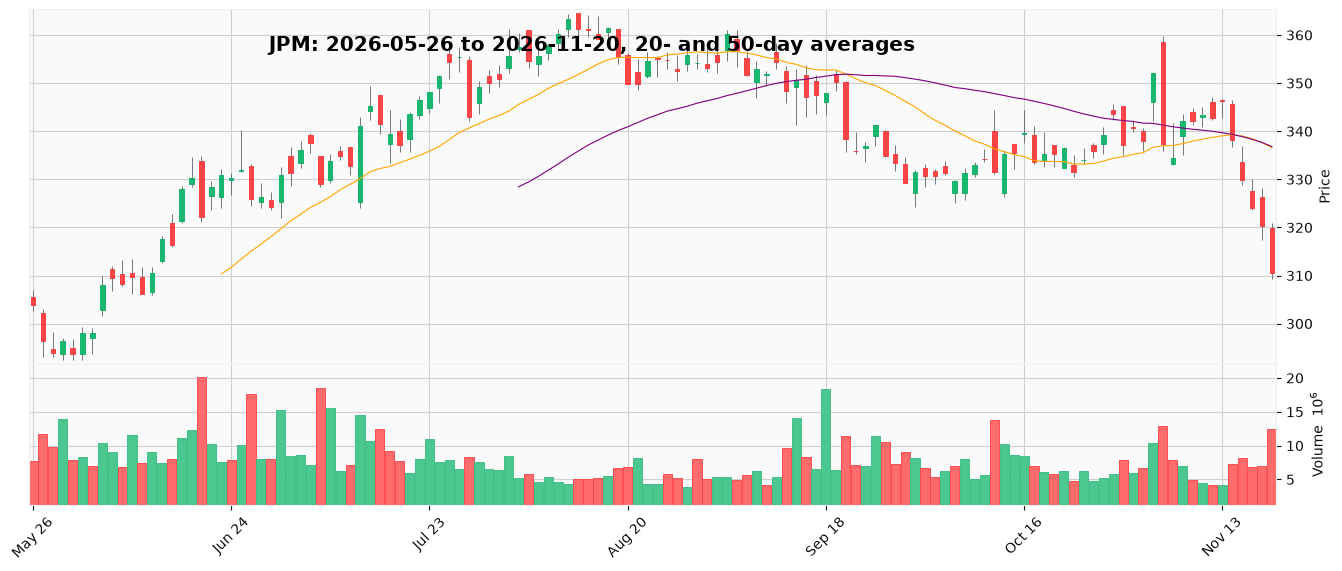

In [7]:
recent = data.tail(126)[["Open", "High", "Low", "Close", "Volume"]]   # about six months of trading days
config.OUTPUT_DIR.mkdir(exist_ok=True)
fig, axes = mpf.plot(
    recent, type="candle", style="yahoo", volume=True,
    mav=(20, 50), mavcolors=["orange", "purple"],
    figratio=(25, 10), tight_layout=True, returnfig=True,
    title=f"{TICKER}: {recent.index[0].date()} to {recent.index[-1].date()}, 20- and 50-day averages",
)
fig.savefig(config.OUTPUT_DIR / f"candlestick_{TICKER}.png", dpi=120)   # for the video
plt.show()

In [8]:
# Numbers quoted in the text below
r = recent["Close"]
print(f"First close {r.iloc[0]:.2f} on {r.index[0].date()}, last close {r.iloc[-1]:.2f} on {r.index[-1].date()}, "
      f"change {100*(r.iloc[-1]/r.iloc[0]-1):.1f}%")
print(f"High {recent['High'].max():.2f} on {recent['High'].idxmax().date()}, low {recent['Low'].min():.2f} on {recent['Low'].idxmin().date()}")
print("Largest absolute daily moves in the window (%):")
print((100 * r.pct_change()).abs().sort_values(ascending=False).head(3).round(2).to_string())
print("Busiest volume days:")
print(recent["Volume"].sort_values(ascending=False).head(3).to_string())

First close 303.85 on 2026-05-26, last close 310.53 on 2026-11-20, change 2.2%
High 364.68 on 2026-08-13, low 292.42 on 2026-05-29
Largest absolute daily moves in the window (%):
Date
2026-11-05    4.19
2026-11-04    4.18
2026-06-16    3.68
Busiest volume days:
Date
2026-06-18    20111000
2026-07-08    18505200
2026-09-18    18312400


**What the chart shows.** JPM rallied strongly from about \$292 at the end of May to a peak near \$365 in mid-August, with the 20-day average above the 50-day average from mid-June onwards. Since then the trend has turned: the 20-day average fell below the 50-day average on 23 September, and the window ends with five falling days in a row (from \$346.19 on 13 November to \$310.53 on 20 November, the last day on the heaviest volume since 5 November), leaving the price well below both averages.

## 4. Stationarity: ADF and KPSS

The two tests ask opposite questions, so we use both:

* **ADF** — null hypothesis: the series has a unit root (is *not* stationary). A p-value **below 0.05** says *stationary*.
* **KPSS** — null hypothesis: the series *is* stationary. A p-value **below 0.05** says *not stationary*.

`statsmodels` reports KPSS p-values only between 0.01 and 0.10 (it reads them from a table), so "0.01" means "0.01 or smaller" and "0.10" means "0.10 or larger".

In [9]:
close = data["Close"]
log_ret = np.log(close).diff().dropna()

rows = []
for name, s in {"Close price": close, "Log return": log_ret}.items():
    adf_stat, adf_p = adfuller(s, autolag="AIC")[:2]
    kpss_stat, kpss_p = kpss(s, regression="c", nlags="auto")[:2]
    adf_ok, kpss_ok = adf_p < 0.05, kpss_p >= 0.05
    verdict = "Stationary" if adf_ok and kpss_ok else "Non-stationary" if not adf_ok and not kpss_ok else "Conflicting"
    rows.append({"Series": name, "ADF statistic": adf_stat, "ADF p-value": adf_p,
                 "KPSS statistic": kpss_stat, "KPSS p-value": kpss_p, "Verdict": verdict})
stationarity = pd.DataFrame(rows).set_index("Series").round(4)
stationarity

,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value,Verdict
Series,,,,,
Close price,0.8381,0.9922,7.3051,0.01,Non-stationary
Log return,-15.5581,0.0000,0.0387,0.10,Stationary


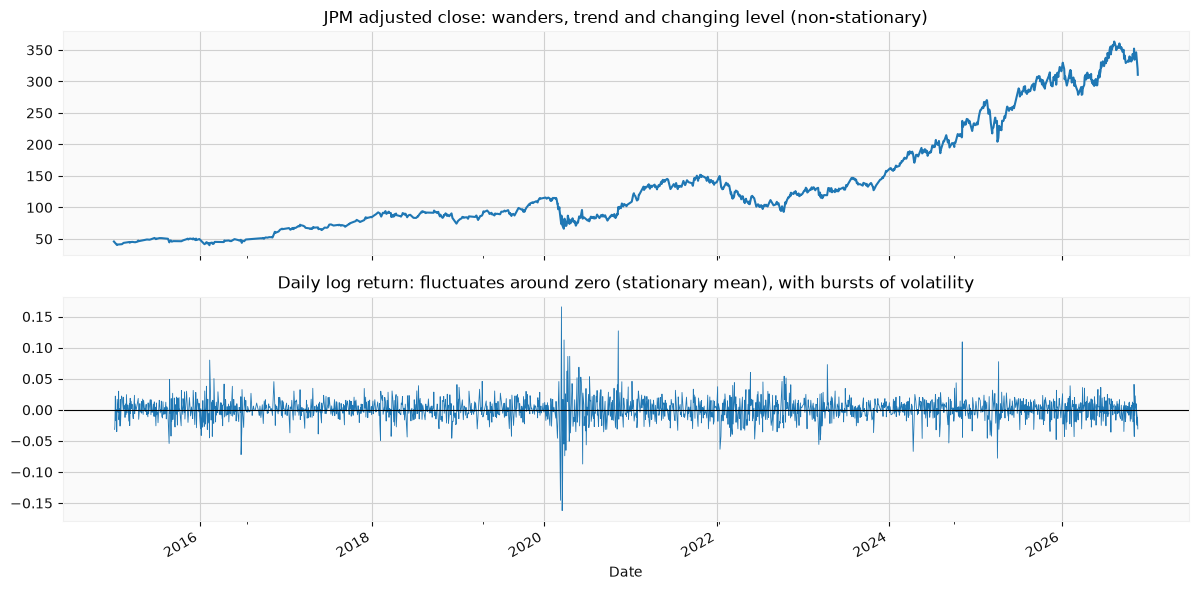

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
close.plot(ax=axes[0], title=f"{TICKER} adjusted close: wanders, trend and changing level (non-stationary)")
log_ret.plot(ax=axes[1], lw=0.6, title="Daily log return: fluctuates around zero (stationary mean), with bursts of volatility")
axes[1].axhline(0, color="black", lw=0.8)
plt.tight_layout(); plt.show()

**Conclusion.** Our data agrees with the theory:

* **Close price — non-stationary.** ADF p = 0.99 (cannot reject a unit root) and KPSS p ≤ 0.01 (rejects stationarity). Both tests agree. The price drifts from about \$46 in January 2015 (adjusted) to over \$300, so its mean is not constant.
* **Log return — stationary.** ADF p < 0.0001 (rejects a unit root) and KPSS p ≥ 0.10 (cannot reject stationarity). Both tests agree.

So **every model in the group forecasts the next-day log return**, and the price forecast is recovered as `last close × exp(predicted log return)`. The return plot also shows that the *variance* is not constant (calm years, then bursts such as March 2020 and November 2026), which is why the feature set includes volatility measures and why the uncertainty range should widen in turbulent periods.

## 5. The feature set

We start from the Notebook 4 feature set (`tslab.features.build_features`) and change one thing on purpose: **every predictor from another market is shifted by one day.**

**How a row is organised.** Row *t* holds what we know at the close of day *t*; the target is the log return from close *t* to close *t+1*. JPM's own price, volume and calendar features use day *t* and earlier, which is known when the forecast for day *t+1* is made, so they are already "lagged" relative to the target.

**Why we still shift the other markets.** Gold (`GC=F`), Brent (`BZ=F`) and the dollar index (`DX-Y.NYB`) are futures/FX series whose daily close on Yahoo Finance is taken *after* the New York stock market closes at 16:00. A same-day value could therefore contain information from after JPM's close, a subtle look-ahead that `check_no_lookahead` cannot see (it only detects rows being used out of order, not clock times). Shifting every outside-market feature by one day removes that risk, and follows the group rule: *every predictor is shifted by at least one day*. The cost is small: we give up same-day S&P 500 and sector information that would have been legitimately known.

| Group | Features | Source | Shift |
|:--|:--|:--|:--|
| `returns` | JPM lagged returns (1–5 days) and 5/10/21/63-day returns | JPM | uses day *t* and earlier |
| `volatility` | rolling volatility 5/21/63 days, vol ratio, high-low range, ATR | JPM | uses day *t* and earlier |
| `technical` | RSI, MACD histogram, Bollinger %B and width, distance from 20/50/200-day averages, overnight gap, intraday move | JPM | uses day *t* and earlier |
| `volume` | volume relative to its 20-day average | JPM | uses day *t* and earlier |
| `other_markets` | S&P 500, tech fund, gold, Brent, dollar 1- and 5-day returns; VIX level and change; 10-year yield level and 5-day change; JPM minus S&P 500 over 5 days | 7 markets | **+1 day** |
| `sector` | XLF (financials fund) 1- and 5-day returns; JPM minus XLF over 5 days | XLF | **+1 day** |
| `calendar` | weekday dummies, month as sine/cosine | the date | known in advance |

In [11]:
OWN_GROUPS = ["returns", "volatility", "technical", "volume", "calendar"]
LEVEL_MARKETS = ["SP500", "TECH", "GOLD", "BRENT", "USD"]


def build_features_jpm(frame):
    # Features for row t use only information available at the close of day t.
    # Outside-market features are shifted by one day (they describe day t-1).
    base = build_features(frame)                       # Notebook 4 features, unchanged
    own = base[[f for g in OWN_GROUPS for f in FEATURE_GROUPS[g]]]

    m = pd.DataFrame(index=frame.index)
    for name in LEVEL_MARKETS:
        m[f"{name}_ret_1d"] = log_return(frame[name], 1)
        m[f"{name}_ret_5d"] = log_return(frame[name], 5)
    m["VIX_level"] = np.log(frame["VIX"])
    m["VIX_change_1d"] = log_return(frame["VIX"], 1)
    m["US10Y_level"] = frame["US10Y"]
    m["US10Y_change_5d"] = frame["US10Y"].diff(5)
    m["relative_to_SP500_5d"] = log_return(frame["Close"], 5) - m["SP500_ret_5d"]
    m["FIN_ret_1d"] = log_return(frame["FIN"], 1)
    m["FIN_ret_5d"] = log_return(frame["FIN"], 5)
    m["relative_to_FIN_5d"] = log_return(frame["Close"], 5) - m["FIN_ret_5d"]

    m = m.shift(1).add_suffix("_lag1")                 # THE SHIFT: yesterday's values only
    return pd.concat([own, m], axis=1)


SECTOR = ["FIN_ret_1d_lag1", "FIN_ret_5d_lag1", "relative_to_FIN_5d_lag1"]
GROUPS_JPM = {g: list(FEATURE_GROUPS[g]) for g in ["returns", "volatility", "technical", "volume"]}
GROUPS_JPM["other_markets"] = [f"{f}_lag1" for f in FEATURE_GROUPS["other_markets"]]
GROUPS_JPM["sector"] = SECTOR
GROUPS_JPM["calendar"] = list(FEATURE_GROUPS["calendar"])
ALL_FEATURES_JPM = [f for g in GROUPS_JPM.values() for f in g]

features = build_features_jpm(data)
assert set(features.columns) == set(ALL_FEATURES_JPM), "group list and feature function disagree"
features = features[ALL_FEATURES_JPM]
print(f"{features.shape[1]} features in {len(GROUPS_JPM)} groups")
pd.DataFrame({"n_features": {g: len(v) for g, v in GROUPS_JPM.items()},
              "features": {g: ", ".join(v) for g, v in GROUPS_JPM.items()}})

50 features in 7 groups


,n_features,features
returns,9,"ret_lag1, ret_lag2, ret_lag3, ret_lag4, ret_la..."
volatility,6,"vol_5d, vol_21d, vol_63d, vol_ratio, range_hl,..."
technical,9,"rsi_14, macd_hist, bb_percent_b, bb_width, dis..."
volume,1,volume_rel_20d
other_markets,15,"SP500_ret_1d_lag1, SP500_ret_5d_lag1, TECH_ret..."
sector,3,"FIN_ret_1d_lag1, FIN_ret_5d_lag1, relative_to_..."
calendar,7,"is_mon, is_tue, is_wed, is_thu, is_fri, month_..."


### 5.1 Look-ahead checks on every feature

**The test.** For a random date *d*, compute the features twice: once from all the data, and once after deleting every row after *d*. An honest feature has the same value on *d* both times. We do this at 25 random dates (seed 42).

1. `tslab.features.check_no_lookahead` on the whole feature function (stops with an error if anything leaks).
2. The same test reported **feature by feature**, so every feature's result is visible.
3. A **negative control**: a deliberately leaky feature (tomorrow's close) must *fail*, which shows the test can catch a leak.

In [12]:
N_CHECKS = 25
result = check_no_lookahead(data, feature_function=build_features_jpm, n_checks=N_CHECKS, seed=SEED)
print(f"check_no_lookahead(build_features_jpm, n_checks={N_CHECKS}) ->", result)

check_no_lookahead(build_features_jpm, n_checks=25) -> True


In [13]:
# Same logic as check_no_lookahead, but recording the largest difference for each feature
rng = np.random.default_rng(SEED)
full = build_features_jpm(data)
valid = np.where(full.notna().all(axis=1))[0]
cuts = rng.choice(valid[valid < len(data) - 10], size=N_CHECKS, replace=False)

max_diff = pd.Series(0.0, index=full.columns)
for pos in cuts:
    truncated = build_features_jpm(data.iloc[: pos + 1])
    diff = (full.iloc[pos] - truncated.iloc[-1]).abs().fillna(np.inf)
    max_diff = np.maximum(max_diff, diff)

group_of = {f: g for g, fs in GROUPS_JPM.items() for f in fs}
lookahead_report = pd.DataFrame({
    "group": [group_of[f] for f in full.columns],
    "shifted_+1_day": [group_of[f] in ("other_markets", "sector") for f in full.columns],
    "max_abs_difference": max_diff.values,
    "result": np.where(max_diff.values <= 1e-9, "PASS", "FAIL"),
}, index=full.columns)
lookahead_report.index.name = "feature"
print(f"Cut dates tested: {sorted(d.date().isoformat() for d in data.index[cuts])}\n")
print(lookahead_report.to_string())
print(f"\n{(lookahead_report.result == 'PASS').sum()} of {len(lookahead_report)} features PASS")
assert (lookahead_report.result == "PASS").all()

Cut dates tested: ['2016-09-26', '2016-10-07', '2016-10-27', '2017-03-16', '2017-10-20', '2018-01-03', '2019-11-19', '2020-07-17', '2020-08-10', '2020-10-05', '2021-04-26', '2021-06-14', '2021-07-30', '2022-12-16', '2023-06-14', '2023-09-12', '2023-11-20', '2024-03-05', '2024-04-11', '2024-06-06', '2024-06-13', '2025-01-23', '2025-03-24', '2026-01-15', '2026-07-16']

                                   group  shifted_+1_day  max_abs_difference result
feature                                                                            
ret_lag1                         returns           False                 0.0   PASS
ret_lag2                         returns           False                 0.0   PASS
ret_lag3                         returns           False                 0.0   PASS
ret_lag4                         returns           False                 0.0   PASS
ret_lag5                         returns           False                 0.0   PASS
ret_5d                           returns  

In [14]:
# Negative control: a feature that uses tomorrow's close must be caught
def leaky_features(frame):
    out = build_features_jpm(frame)
    out["LEAK_tomorrow_return"] = np.log(frame["Close"].shift(-1) / frame["Close"])
    return out

try:
    check_no_lookahead(data, feature_function=leaky_features, n_checks=N_CHECKS, seed=SEED)
    print("Leak NOT detected (this would be a problem)")
except AssertionError as error:
    print("Leak detected, as expected:\n ", error)

Leak detected, as expected:
  Look-ahead bias detected on 2023-06-14: these features changed when the future was removed: ['LEAK_tomorrow_return']


## 6. The dataset for the models, and the saved files

`make_dataset` in `tslab` adds the targets for one horizon. We add the targets for **all four horizons** used by the group (1, 5, 21, 63 days), so Mark M. can use the same file for the multi-horizon work:

* `target_return` = log(close *t+1* / close *t*) — **the main target** (same as `target_return_h1`)
* `target_close` = close on day *t+1*
* `target_return_h5`, `_h21`, `_h63` = log(close *t+h* / close *t*)

Targets are the only columns that look forward (`shift(-h)`); they are answers, never inputs. Rows are kept from the first day on which every feature exists (the 200-day average needs 200 days of history). The **last rows have no target yet**, because that future has not happened: they are kept so that the final forecast can be made from the last known day.

In [15]:
HORIZONS = [1, 5, 21, 63]

dataset = features.copy()
dataset["close"] = data["Close"]
dataset["target_close"] = data["Close"].shift(-1)
dataset["target_return"] = np.log(data["Close"].shift(-1) / data["Close"])
for h in HORIZONS:
    dataset[f"target_return_h{h}"] = np.log(data["Close"].shift(-h) / data["Close"])
dataset = dataset.replace([np.inf, -np.inf], np.nan)
dataset = dataset[dataset[ALL_FEATURES_JPM].notna().all(axis=1)]
dataset.index.name = "Date"

assert dataset[ALL_FEATURES_JPM].notna().all().all()
assert np.allclose(dataset["target_return"].dropna(), dataset["target_return_h1"].dropna())
n_train_rows = dataset["target_return"].notna().sum()
print(f"Rows: {len(dataset)} ({dataset.index.min().date()} to {dataset.index.max().date()}), "
      f"rows with a 1-day target: {n_train_rows}")
print("Missing targets at the end:", {c: int(dataset[c].isna().sum()) for c in dataset.columns if c.startswith("target")})
print(f"INITIAL_TRAIN = {config.INITIAL_TRAIN} rows -> first test day {dataset.index[config.INITIAL_TRAIN].date()}, "
      f"{n_train_rows - config.INITIAL_TRAIN} out-of-sample days for the 1-day walk-forward")

Rows: 2791 (2015-10-16 to 2026-11-20), rows with a 1-day target: 2790
Missing targets at the end: {'target_close': 1, 'target_return': 1, 'target_return_h1': 1, 'target_return_h5': 5, 'target_return_h21': 21, 'target_return_h63': 63}
INITIAL_TRAIN = 1000 rows -> first test day 2019-10-08, 1790 out-of-sample days for the 1-day walk-forward


In [16]:
features_path = config.DATA_DIR / f"features_{TICKER}.csv"   # CSV: needs no package beyond the lab's requirements
groups_path = config.DATA_DIR / f"feature_groups_{TICKER}.json"

dataset.to_csv(features_path)
with open(groups_path, "w") as f:
    json.dump({
        "ticker": TICKER, "download_date": DOWNLOAD_DATE, "seed": SEED,
        "first_date": str(dataset.index.min().date()), "last_date": str(dataset.index.max().date()),
        "main_target": "target_return",
        "targets": ["target_return", "target_close"] + [f"target_return_h{h}" for h in HORIZONS],
        "groups": GROUPS_JPM, "all_features": ALL_FEATURES_JPM,
    }, f, indent=2)

# Round-trip check: what teammates load is what we built
reloaded = pd.read_csv(features_path, index_col="Date", parse_dates=True)
pd.testing.assert_frame_equal(reloaded, dataset, check_freq=False, check_exact=False, rtol=1e-12)
print("Saved", features_path.name, reloaded.shape, "and", groups_path.name)

Saved

 features_JPM.csv (2791, 57) and feature_groups_JPM.json


### How teammates use these files

```python
import json, pandas as pd
from tslab import config

data = pd.read_csv(config.DATA_DIR / "features_JPM.csv", index_col="Date", parse_dates=True)
groups = json.load(open(config.DATA_DIR / "feature_groups_JPM.json"))
FEATURES = groups["all_features"]

train_ready = data.dropna(subset=["target_return"])     # NOT data.dropna(): that would also drop
X, y = train_ready[FEATURES], train_ready["target_return"]  # the last 63 rows that lack a 63-day target

# Multi-horizon (Mark M.): use target_return_h{h} and dropna on that column only.
# Price forecast: data["close"] * np.exp(predicted log return)
```

The last row (`dataset.index[-1]`) has features but no target: it is the input for the forecast of the next trading day.

## 7. Summary (Member 1 deliverables)

| Check | Result |
|:--|:--|
| Stock and justification | JPM, largest US bank, financials sector, very liquid, 11.9 years of clean history |
| Download date | 23 November 2026 (Yahoo Finance, adjusted prices, 2 Jan 2015 – 20 Nov 2026) |
| Quality | 2,990 days; no duplicates, missing values, bad prices or zero-volume days; gaps are NYSE holidays only |
| `INITIAL_TRAIN` | Kept at 1,000 rows (history is far longer than 4 years); first test day 8 Oct 2019, 1,790 out-of-sample days |
| Stationarity | Close non-stationary, log return stationary (ADF and KPSS agree) → we forecast log returns |
| Features | 50 features in 7 groups (Notebook 4 set + XLF sector group); all outside-market features shifted by one day |
| Look-ahead | `check_no_lookahead` → `True`; all 50 features PASS individually at 25 dates; a planted leak is caught |
| Seed | 42 |
| Files | `data/target_JPM.csv`, `data/predictors.csv`, `data/sector_XLF.csv`, `data/features_JPM.csv` (2,791 rows × 57 columns), `data/feature_groups_JPM.json` |

**Limitations to mention in the report.** The data covers one stock in one country and is dominated by two regimes (the 2020 shock and the 2022–2026 period of higher interest rates). Adjusted prices are rewritten when dividends are paid, which is why the snapshot is frozen at the download date. Same-day outside-market information is deliberately not used, which is the safe choice but could slightly understate what a model could do in real time.